# Bubble Soccer WA - DIV 1 Ladder Graphic

Reads the ladder from `data/div1_ladder.csv` and draws it onto the 1080x1080 template `assets/template_div1.png`, with the points (PTS) column in bold.

The drawing code lives in [`ladder.py`](ladder.py) so this notebook and the Streamlit app (`app.py`) share it. Install the packages with `pip install -r requirements.txt`.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display
from PIL import Image

from ladder import COLUMNS, DEFAULT_CSV, DEFAULT_TEMPLATE, clean_ladder, render_ladder

OUTPUT_PATH = Path("output") / "ladder_graphic.png"

## Load the ladder

`clean_ladder` drops empty rows and makes every stat a whole number.

In [2]:
ladder = clean_ladder(pd.read_csv(DEFAULT_CSV)).sort_values("index").reset_index(drop=True)
ladder

,index,teamname,p,w,d,l,gd,pts
0,1,Perth Pythons,10,8,1,1,22,25
1,2,Fremantle Falcons,10,7,2,1,18,23
2,3,Joondalup Jets,10,6,2,2,11,20
3,4,Rockingham Rhinos,10,5,2,3,6,17
4,5,Mandurah Mariners,10,4,3,3,2,15
5,6,Subiaco Stingrays,10,4,1,5,-3,13
6,7,Midland Magpies,10,3,2,5,-7,11
7,8,Bunbury Bulls,10,2,3,5,-9,9
8,9,Armadale Avalanche,10,2,1,7,-16,7
9,10,Wanneroo Wolves,10,1,1,8,-24,4


## Fonts and layout

Poppins (bundled in `assets/fonts/`) matches the template title. Each column is placed at a fixed x position on the 1080px canvas:

In [3]:
pd.DataFrame(COLUMNS, columns=["label", "csv column", "x", "alignment"])

,label,csv column,x,alignment
0,#,index,105,center
1,TEAM,teamname,160,left
2,P,p,590,center
3,W,w,660,center
4,D,d,730,center
5,L,l,800,center
6,GD,gd,875,center
7,PTS,pts,965,center


## Draw the table

`render_ladder` draws the header, striped rows and highlighted points column on a transparent overlay, then composites it over the template.

In [4]:
graphic = render_ladder(ladder, Image.open(DEFAULT_TEMPLATE))
graphic.size

(1080, 1080)

## Save and preview

Saved output/ladder_graphic.png (1080x1080)


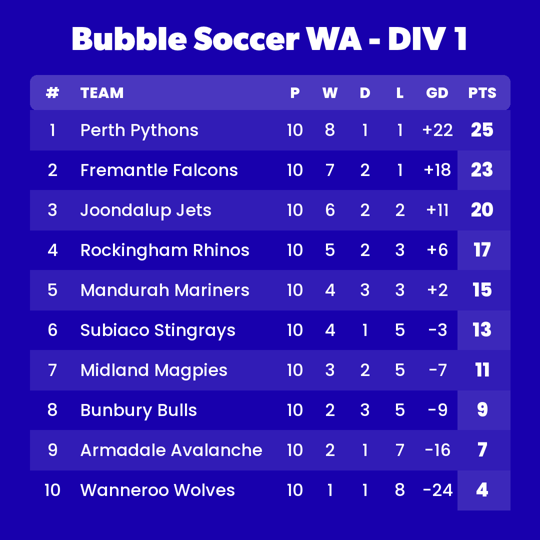

In [5]:
OUTPUT_PATH.parent.mkdir(exist_ok=True)
graphic.save(OUTPUT_PATH)
print(f"Saved {OUTPUT_PATH} ({graphic.width}x{graphic.height})")
display(graphic.resize((540, 540)))